# Figure S2 — Filtering of the 10 kb TSS regions

- a: genomic coverage of the ENCODE blacklist vs the GC-correction exclusion list, per chromosome;
- b: Venn diagram of TSS windows overlapping each list;
- c: per-TSS mean vs standard deviation of coverage across the panel of normals, coloured by filter category.

Source data, written by `export/export_figS2.py` from the filter files in `accessory_files/` (derived by `src/comp/derive_tss_filter.py`, see the README there):
- `data/figS2a_blacklist_per_chrom.csv` — bp per chromosome per list (interval-length sums);
- `data/figS2b_venn_counts.csv` — overlapping-entry counts;
- `data/figS2c_tss_qc.csv` — one row per TSS window: PoN coverage mean/SD and filter-category membership (blacklist / another TSS within 5 kb / chrX / high variability, SD ≥ 99.5th percentile).

Run top to bottom from `src/figures/`.

In [1]:
import os

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import _figstyle as fs           # applied inside the Fig S2 cell only
from matplotlib_venn import venn2
from scipy import stats

s2a = pd.read_csv("data/figS2a_blacklist_per_chrom.csv")
s2b = pd.read_csv("data/figS2b_venn_counts.csv")
s2c = pd.read_csv("data/figS2c_tss_qc.csv")
print(f"S2c: {len(s2c)} windows, removed {int(s2c['removed'].sum())}, "
      f"retained {int((~s2c['removed']).sum())}")

S2c: 19376 windows, removed 5150, retained 14226


## Panel a — blacklist coverage per chromosome

In [2]:
def chrom_sort_key(c):
    v = c.replace("chr", "")
    return 23 if v == "X" else int(v)


ENC_COLOR, GC_COLOR = "#440154", "#FDE725"


def panel_a(ax):
    d = s2a.copy()
    d["order"] = d["chrom"].map(chrom_sort_key)
    d = d.sort_values("order")
    x = np.arange(len(d))
    w = 0.4
    total_enc = d["encode_blacklist_bp"].sum()
    total_gc = d["gc_exclusion_bp"].sum()
    # bars in Mb for readability; the totals in the legend are the exact bp sums
    ax.bar(x - w / 2, d["encode_blacklist_bp"] / 1e6, width=w, color=ENC_COLOR,
           label=f"ENCODE blacklist ({total_enc:,} bp in total)")
    ax.bar(x + w / 2, d["gc_exclusion_bp"] / 1e6, width=w, color=GC_COLOR, edgecolor="#b8a300", linewidth=0.3,
           label=f"GCparagon exclusion list ({total_gc:,} bp in total)")
    ax.set_xticks(x)
    ax.set_xticklabels(d["chrom"].str.replace("chr", ""))
    ax.set_xlim(-0.7, len(d) - 0.3)
    ax.set_xlabel("Chromosome")
    ax.set_ylabel("Base pairs covered (Mb)")
    ax.legend(loc="upper right")
    fs.value_grid(ax)


## Panel b — Venn of TSS windows overlapping each blacklist

In [3]:
def panel_b(ax):
    gc_only = int(s2b["gc_only"].iloc[0])
    enc_only = int(s2b["encode_only"].iloc[0])
    both = int(s2b["both"].iloc[0])
    v = venn2(subsets=(gc_only, enc_only, both),
              set_labels=("GCparagon\nexclusion list", "ENCODE\nblacklist"),
              set_colors=(GC_COLOR, ENC_COLOR), alpha=0.6, ax=ax)
    for t in v.subset_labels:
        if t is not None:
            t.set_fontsize(fs.VALUE)
    for t in v.set_labels:
        if t is not None:
            t.set_fontsize(fs.SMALL)
    # the ENCODE-only count (0) sits on the circle edge: move it just outside, right of the circles
    lab = v.get_label_by_id("01")
    if lab is not None:
        x, y = lab.get_position()
        lab.set_position((x + 0.06, y))
        lab.set_ha("left")


## Panel c — QC filter scatter (mean vs SD of PoN coverage)

In [4]:
def panel_c(ax):
    n_ret = int((~s2c["removed"]).sum())
    n_ovl = int(s2c["in_overlapping"].sum())
    n_x = int(s2c["in_chrX"].sum())
    n_hv = int(s2c["in_high_variability"].sum())
    n_bl = int(s2c["in_blacklist"].sum())
    n_multi = int((s2c[["in_blacklist", "in_chrX", "in_overlapping",
                        "in_high_variability"]].sum(axis=1) > 1).sum())

    # colours and legend order of the filter categories
    ret = s2c[~s2c["removed"]]
    ax.scatter(ret["mean_coverage"], ret["std_coverage"], s=1.5, alpha=0.4, lw=0,
               color="#C8C8C8", label=f"Retained (n = {n_ret:,})", zorder=2, rasterized=True)
    ovl = s2c[s2c["in_overlapping"]]
    ax.scatter(ovl["mean_coverage"], ovl["std_coverage"], s=2.5, alpha=0.75, lw=0,
               color="#9B6FD0", marker="s",
               label=f"Another TSS within 5 kb (n = {n_ovl:,})", zorder=3, rasterized=True)
    chrx = s2c[s2c["in_chrX"]]
    ax.scatter(chrx["mean_coverage"], chrx["std_coverage"], s=3, alpha=0.75, lw=0,
               color="#F58A1F", marker="^",
               label=f"Chromosome X (n = {n_x})", zorder=3, rasterized=True)
    hv = s2c[s2c["in_high_variability"]]
    ax.scatter(hv["mean_coverage"], hv["std_coverage"], s=6, alpha=0.9, lw=0,
               color="#2CA02C", marker="D",
               label=f"High variability\n(SD ≥ 99.5th percentile, n = {n_hv})", zorder=5)
    bl = s2c[s2c["in_blacklist"]]
    ax.scatter(bl["mean_coverage"], bl["std_coverage"], s=3, alpha=0.8,
               color="black", marker="x", linewidths=0.4,
               label=f"Exclusion lists (n = {n_bl:,})", zorder=4, rasterized=True)

    valid = s2c.dropna(subset=["mean_coverage", "std_coverage"])
    r, p = stats.pearsonr(valid["mean_coverage"], valid["std_coverage"])
    slope, intercept = np.polyfit(valid["mean_coverage"], valid["std_coverage"], 1)
    xs = np.linspace(0, 2.5, 50)
    p_str = "p < 0.001" if p < 0.001 else f"p = {p:.3g}"
    ax.plot(xs, slope * xs + intercept, color="#2E5FA3", linewidth=1.0, zorder=6,
            label=f"Least-squares fit\n(Pearson r = {r:.3f}, {p_str})")

    # a handful of extreme windows (all removed) fall outside the view
    ax.set_xlim(0, 2.5)
    ax.set_ylim(0, 0.85)

    ax.set_xlabel("Mean coverage across the panel of normals")
    ax.set_ylabel("SD of coverage across the panel of normals")
    summary = (f"Total TSS windows: {len(s2c):,}\n"
               f"Removed: {int(s2c['removed'].sum()):,} ({100 * s2c['removed'].mean():.1f}%)\n"
               f"Retained: {n_ret:,} ({100 * (1 - s2c['removed'].mean()):.1f}%)\n"
               f"Removed by multiple filters: {n_multi}")
    return r, summary


saved output/figS2.png/.pdf at 178 x 127 mm


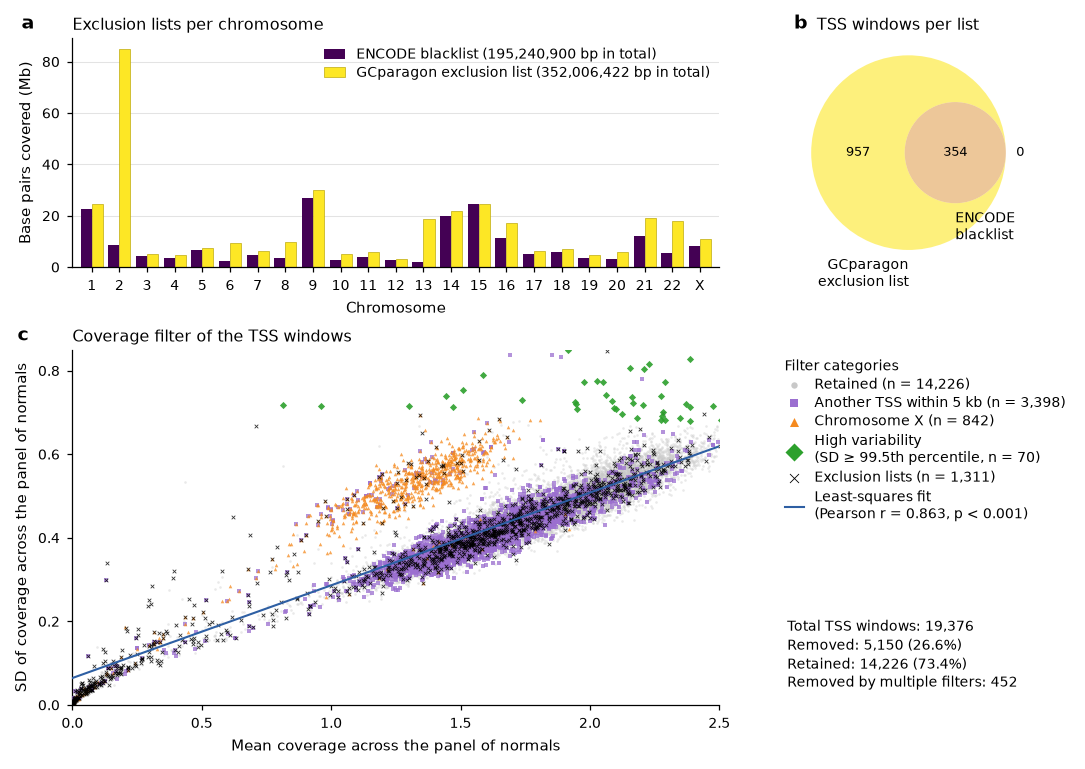

In [5]:
# Drawn at print size (180 mm wide) in the shared style, inside an rc_context.
with mpl.rc_context():
    fs.apply()
    fig = plt.figure(figsize=fs.size(height=5.0), layout="constrained")
    gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.75], height_ratios=[1, 1.55])
    ax_a = fig.add_subplot(gs[0, :2])
    ax_b = fig.add_subplot(gs[0, 2])
    ax_c = fig.add_subplot(gs[1, :2])
    ax_leg = fig.add_subplot(gs[1, 2])
    panel_a(ax_a)
    panel_b(ax_b)
    r, summary = panel_c(ax_c)
    fs.panel(ax_a, "a", "Exclusion lists per chromosome")
    fs.panel(ax_b, "b", "TSS windows per list")
    ax_b.set_title("TSS windows per list", loc="left", pad=4, x=0.1)   # the Venn axes have no tick labels: keep the title clear of the letter
    fs.panel(ax_c, "c", "Coverage filter of the TSS windows")
    # legend and counts of panel c in the free cell to its right
    ax_leg.axis("off")
    handles, labels = ax_c.get_legend_handles_labels()
    leg = ax_leg.legend(handles, labels, title="Filter categories", loc="upper left", bbox_to_anchor=(-0.05, 1.0),
                        alignment="left", markerscale=2.5, handlelength=1.4)
    for h in leg.legend_handles:
        if hasattr(h, "set_alpha"):
            h.set_alpha(1)
    ax_leg.text(0.0, 0.25, summary, transform=ax_leg.transAxes, ha="left", va="top", fontsize=fs.SMALL, linespacing=1.4)
    os.makedirs("output", exist_ok=True)
    fs.save(fig, "output/figS2")
plt.show()


## Checks

Asserts the filter-category counts in `figS2c_tss_qc.csv`; the `in_submitted_*` columns hold the earlier filter's counts. Pearson r is printed, not asserted.

In [6]:
checks = {
    "total windows": (len(s2c), 19376),
    "blacklist": (int(s2c["in_blacklist"].sum()), 1311),
    "overlapping (<5kb)": (int(s2c["in_overlapping"].sum()), 3398),
    "chrX": (int(s2c["in_chrX"].sum()), 842),
    "multiple filters": (int((s2c[["in_blacklist", "in_chrX", "in_overlapping",
                                   "in_high_variability"]].sum(axis=1) > 1).sum()), 452),
    "high variability (regenerated)": (int(s2c["in_high_variability"].sum()), 70),
    "removed (regenerated)": (int(s2c["removed"].sum()), 5150),
    "retained (regenerated)": (int((~s2c["removed"]).sum()), 14226),
    "removed (submitted)": (int(s2c["in_submitted_removed"].sum()), 5152),
    "high variability (submitted)": (int(s2c["in_submitted_high_variability"].sum()), 72),
}
for key, (got, want) in checks.items():
    flag = "OK" if got == want else "MISMATCH"
    print(f"  {key:<32} {got:>6}  (expected {want:>6})  {flag}")
    assert got == want, f"{key}: {got} != {want}"
print(f"  Pearson r                        {r:.3f}  (manuscript  0.904, historical panel)")


  total windows                     19376  (expected  19376)  OK
  blacklist                          1311  (expected   1311)  OK
  overlapping (<5kb)                 3398  (expected   3398)  OK
  chrX                                842  (expected    842)  OK
  multiple filters                    452  (expected    452)  OK
  high variability (regenerated)       70  (expected     70)  OK
  removed (regenerated)              5150  (expected   5150)  OK
  retained (regenerated)            14226  (expected  14226)  OK
  removed (submitted)                5152  (expected   5152)  OK
  high variability (submitted)         72  (expected     72)  OK
  Pearson r                        0.863  (manuscript  0.904, historical panel)
